# Cvičenie III - Viacrozmerné a stavové modely

## Viacrozmerné časové rady a ich analýza

Kým jednorozmerný časový rad sleduje vývoj jednej premennej, napríklad ceny akcie, viacrozmerný sleduje súčasne dve alebo viac premenných, ako napríklad ceny viacerých akcií, vývoj inflácie a úrokových sadzieb alebo vzťah medzi spotrebou a príjmom domácností.

Hlavnou myšlienkou viacrozmernej analýzy je, že vývoj jednej premennej môže súvisieť nielen s jej vlastnou minulosťou, ale aj s minulými hodnotami ostatných premenných.

----------
### CCF

Pri analýze viacrozmerných časových radov nás zaujíma nielen vývoj jednotlivých premenných, ale aj ich vzájomné vzťahy v čase. Jedným zo spôsobov, ako tieto vzťahy skúmať je krížová korelačná funkcia (CCF).

Funkcia umožňuje skúmať lineárnu závislosť medzi dvoma časovými radmi pri rôznych časových lagoch. Postupne porovnávame hodnoty jednej premennej s časovo posunutými hodnotami druhej premennej a sledujeme, pri ktorých oneskoreniach je ich vzájomná korelácia najvýraznejšia.

$$
\rho_{XY}(h) = \operatorname{Corr}(X_t, Y_{t-h})
$$

Predpokladajme, že pozorujeme nasledujúce denné dáta:

| Deň | Reklama ($X$) | Tržby ($Y$) |
| :---: | :---: | :---: |
| **1** | 10 | 0 |
| **2** | 0 | 0 |
| **3** | 0 | 10 |
| **4** | 20 | 0 |
| **5** | 0 | 0 |
| **6** | 0 | 20 |
| **7** | 15 | 0 |
| **8** | 0 | 0 |
| **9** | 0 | 15 |

* Reklama v čase $t$ sa prejaví na tržbách presne o **2 dni neskôr** ($t+2$).



## Viacrozmerné časové rady a ich analýza

Kým jednorozmerný časový rad sleduje vývoj jednej premennej, napríklad ceny akcie, viacrozmerný sleduje súčasne dve alebo viac premenných, ako napríklad ceny viacerých akcií, vývoj inflácie a úrokových sadzieb alebo vzťah medzi spotrebou a príjmom domácností.

Hlavnou myšlienkou viacrozmernej analýzy je, že vývoj jednej premennej môže súvisieť nielen s jej vlastnou minulosťou, ale aj s minulými hodnotami ostatných premenných.

Načítaných pozorovaní: 437
Obdobie: 2025-01-02 až 2026-09-30
Lag s maximálnou absolútnou hodnotou CCF:


,lag_max_abs_CCF,CCF
dvojica,,
XLK-XLV,-15,0.1565
SMH-SOXX,-15,0.9845
FXE-XLY,0,0.0113


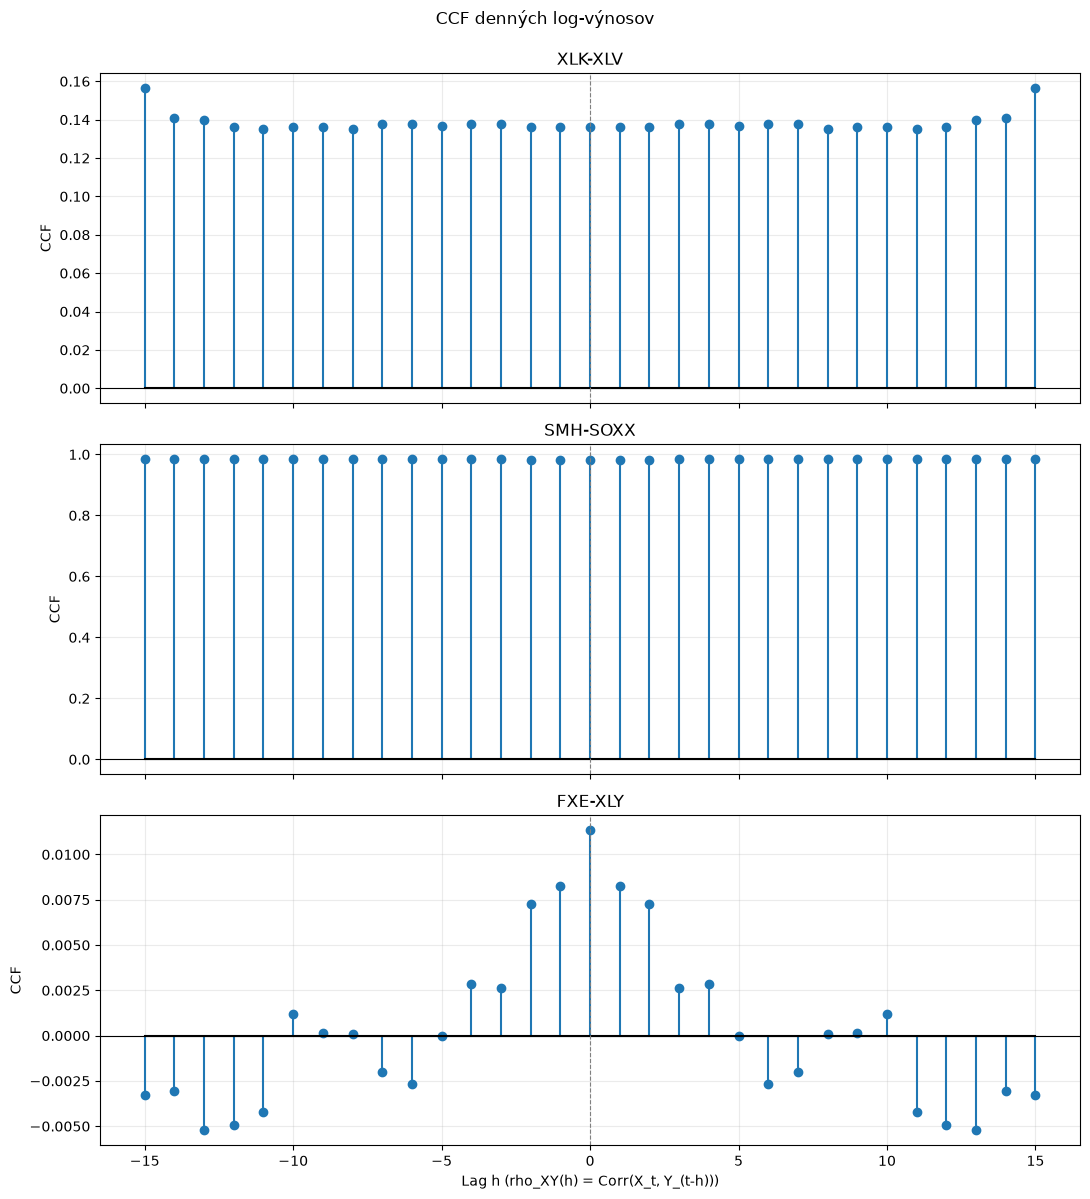

Korelácia sama osebe nedokazuje kauzalitu: môže byť spôsobená spoločným tretím faktorom, spätnou väzbou, trendom alebo náhodou. Lag iba opisuje časovú asociáciu; na kauzálne tvrdenie treba ďalšie predpoklady a vhodný identifikačný experiment/model.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

tickers = ["XLK", "XLV", "SMH", "SOXX", "FXE", "XLY"]
# yfinance má parameter end exkluzívny, preto použijeme 2026-10-01.
prices = yf.download(
    tickers, start="2025-01-01", end="2026-10-01",
    auto_adjust=True, progress=False
)["Close"]
if prices.empty:
    raise ValueError("yfinance nevrátil žiadne údaje.")
prices = prices[tickers].dropna()
print(f"Načítaných pozorovaní: {len(prices)}")
print(f"Obdobie: {prices.index.min().date()} až {prices.index.max().date()}")

# rho_XY(h) = Corr(X_t, Y_(t-h)); kladný lag posúva druhý rad dozadu.
def ccf_at_lag(x, y, lag):
    if lag > 0:
        return x.iloc[lag:].corr(y.iloc[:-lag])
    if lag < 0:
        return x.iloc[:lag].corr(y.iloc[-lag:])
    return x.corr(y)

lags = np.arange(-15, 16)
pairs = [("XLK", "XLV"), ("SMH", "SOXX"), ("FXE", "XLY")]
ccf_results = {}
for first, second in pairs:
    # Výnosy používame namiesto cien, aby sme sa vyhli spurious korelácii trendov.
    returns = np.log(prices[[first, second]]).diff().dropna()
    name = f"{first}-{second}"
    ccf_results[name] = pd.Series(
        [ccf_at_lag(returns[first], returns[second], int(lag)) for lag in lags],
        index=lags,
    )

ccf_table = pd.DataFrame(ccf_results)
max_lags = pd.DataFrame([
    {"dvojica": name,
     "lag_max_abs_CCF": int(values.abs().idxmax()),
     "CCF": values.loc[values.abs().idxmax()]}
    for name, values in ccf_table.items()
]).set_index("dvojica")
print("Lag s maximálnou absolútnou hodnotou CCF:")
display(max_lags.round(4))

fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)
for ax, (name, values) in zip(axes, ccf_table.items()):
    ax.stem(lags, values, linefmt="C0-", markerfmt="C0o", basefmt="k-")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.set_ylabel("CCF")
    ax.set_title(name)
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("Lag h (rho_XY(h) = Corr(X_t, Y_(t-h)))")
fig.suptitle("CCF denných log-výnosov", y=0.995)
fig.tight_layout()
plt.show()

print("Korelácia sama osebe nedokazuje kauzalitu: môže byť spôsobená "
      "spoločným tretím faktorom, spätnou väzbou, trendom alebo náhodou. "
      "Lag iba opisuje časovú asociáciu; na kauzálne tvrdenie treba "
      "ďalšie predpoklady a vhodný identifikačný experiment/model.")

-------
### Kointegrácia

Pri analýze časových radov mnohé premenné vykazujú v čase trend, čo znamená, že sú nestacionárne. Táto nestacionarita môže predstavovať problém pri tvorbe štatistických modelov, pretože môže viesť k zavádzajúcim výsledkom. Niekedy sa však dva alebo viaceré nestacionárne časové rady vyvíjajú spoločne takým spôsobom, že ich kombinácia je stacionárna. Tento vzťah nazývame kointegrácia.


Johansenov test slúži na overenie existencie dlhodobých vzťahov medzi viacerými nestacionárnymi časovými radmi, ktoré sú integrované rádu $I(1)$. Test určuje počet nezávislých kointegračných vzťahov, tzv. kointegračný rank $r$.


Pri troch časových radoch testujeme postupne tieto hypotézy:
| Nulová hypotéza $H_0$ |
|---|
| $r = 0$ | 
| $r \leq 1$ | 
| $r \leq 2$ |

- $r = 0$: neidentifikovali sme žiadny kointegračný vzťah.
- $r = 1$: existuje jeden kointegračný vzťah.
- $r = 2$: existujú dva nezávislé kointegračné vzťahy.
- $r = 3$: plný rank.

Pri testovaní používame pôvodné cenové úrovne alebo ich logaritmy, nie prvé diferencie a kointegračný rank určujeme podľa prvej nezamietnutej hypotézy.

| Situácia | Model 
| :--- | :--- |
| Rady sú stacionárne, $I(0)$ | **VAR v úrovniach** *(VAR in levels)* |
| Rady sú nestacionárne, $I(1)$, a **nie sú** kointegrované | **VAR v prvých diferenciách** *(VAR in differences)* | 
| Rady sú nestacionárne, $I(1)$, a **sú** kointegrované | **VECM** *(Vector Error Correction Model)* |


In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.vector_ar.vecm import coint_johansen

groups = {
    "SPY-IVV-VOO": ["SPY", "IVV", "VOO"],
    "SPY-GLD-TLT": ["SPY", "GLD", "TLT"],
}
all_tickers = sorted({ticker for group in groups.values() for ticker in group})

# The end date is exclusive in yfinance, so 2026-10-01 includes 30 September.
prices = yf.download(
    all_tickers, start="2020-01-01", end="2026-10-01",
    auto_adjust=True, progress=False
)["Close"]
if prices.empty:
    raise ValueError("yfinance returned no data.")
prices = prices[all_tickers].dropna()
print(f"Observations: {len(prices)}")
print(f"Period: {prices.index.min().date()} to {prices.index.max().date()}")

def adf_result(series):
    statistic, pvalue, used_lag, nobs, critical_values, _ = adfuller(
        series.dropna(), autolag="AIC"
    )
    return {
        "ADF statistic": statistic,
        "p-value": pvalue,
        "lags": used_lag,
        "stationary at 5%": pvalue < 0.05,
    }

adf_rows = []
for group_name, tickers_in_group in groups.items():
    for ticker in tickers_in_group:
        level_result = adf_result(prices[ticker])
        difference_result = adf_result(prices[ticker].diff())
        adf_rows.extend([
            {"group": group_name, "ticker": ticker, "series": "level", **level_result},
            {"group": group_name, "ticker": ticker, "series": "first difference", **difference_result},
        ])

adf_table = pd.DataFrame(adf_rows)
print("ADF tests (H0: unit root / non-stationarity):")
display(adf_table.round(4))

def johansen_rank(result, alpha_index=1):
    """Return the first rank whose trace statistic does not reject H0."""
    for rank, (trace_stat, critical_value) in enumerate(
        zip(result.lr1, result.cvt[:, alpha_index])
    ):
        if trace_stat <= critical_value:
            return rank
    return len(result.lr1)

rank_rows = []
johansen_results = {}
for group_name, tickers_in_group in groups.items():
    group_prices = prices[tickers_in_group]
    result = coint_johansen(group_prices, det_order=0, k_ar_diff=1)
    johansen_results[group_name] = result
    rank = johansen_rank(result)
    rank_rows.append({"group": group_name, "cointegration rank r": rank})

    trace_table = pd.DataFrame({
        "H0": [f"r <= {i}" for i in range(len(result.lr1))],
        "trace statistic": result.lr1,
        "5% critical value": result.cvt[:, 1],
        "reject at 5%": result.lr1 > result.cvt[:, 1],
    })
    print(f"Johansen trace test: {group_name} (det_order=0, k_ar_diff=1)")
    display(trace_table.round(4))
    print(f"Estimated cointegration rank: r = {rank}\n")

rank_table = pd.DataFrame(rank_rows).set_index("group")
display(rank_table)

for group_name, rank in rank_table["cointegration rank r"].items():
    level_stationary = adf_table.query(
        "group == @group_name and series == 'level'"
    )["stationary at 5%"].all()
    if level_stationary:
        recommendation = "VAR in levels (the series are stationary)."
    elif rank > 0:
        recommendation = "VECM (the series are non-stationary and cointegrated)."
    else:
        recommendation = "VAR in first differences (no cointegration detected)."
    print(f"{group_name}: {recommendation}")

Observations: 1695
Period: 2020-01-02 to 2026-09-30


C:\Users\Admin\AppData\Local\Temp\ipykernel_21292\2852837861.py:25: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, pvalue, used_lag, nobs, critical_values, _ = adfuller(
C:\Users\Admin\AppData\Local\Temp\ipykernel_21292\2852837861.py:25: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, pvalue, used_lag, nobs, critical_values, _ = adfuller(
C:\Users\Admin

ADF tests (H0: unit root / non-stationarity):


C:\Users\Admin\AppData\Local\Temp\ipykernel_21292\2852837861.py:25: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, pvalue, used_lag, nobs, critical_values, _ = adfuller(
C:\Users\Admin\AppData\Local\Temp\ipykernel_21292\2852837861.py:25: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, pvalue, used_lag, nobs, critical_values, _ = adfuller(
C:\Users\Admin

,group,ticker,series,ADF statistic,p-value,lags,stationary at 5%
0,SPY-IVV-VOO,SPY,level,0.4613,0.9836,9,False
1,SPY-IVV-VOO,SPY,first difference,-13.8828,0.0000,8,True
2,SPY-IVV-VOO,IVV,level,0.4648,0.9838,9,False
3,SPY-IVV-VOO,IVV,first difference,-13.8433,0.0000,8,True
4,SPY-IVV-VOO,VOO,level,0.4601,0.9836,9,False
5,SPY-IVV-VOO,VOO,first difference,-13.8043,0.0000,8,True
6,SPY-GLD-TLT,SPY,level,0.4613,0.9836,9,False
7,SPY-GLD-TLT,SPY,first difference,-13.8828,0.0000,8,True
8,SPY-GLD-TLT,GLD,level,0.0307,0.9610,23,False
9,SPY-GLD-TLT,GLD,first difference,-8.3800,0.0000,22,True


...

c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\vector_ar\vecm.py:717: ComplexWarning: Casting complex values to real discards the imaginary part
  lr1[i] = -t * np.sum(tmp, 0)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\vector_ar\vecm.py:718: ComplexWarning: Casting complex values to real discards the imaginary part
  lr2[i] = -t * np.log(1 - a[i])


,H0,trace statistic,5% critical value,reject at 5%
0,r <= 0,10.8322,29.7961,False
1,r <= 1,3.1480,15.4943,False
2,r <= 2,0.4208,3.8415,False


Estimated cointegration rank: r = 0



,cointegration rank r
group,
SPY-IVV-VOO,2
SPY-GLD-TLT,0


SPY-IVV-VOO: VECM (the series are non-stationary and cointegrated).
SPY-GLD-TLT: VAR in first differences (no cointegration detected).


Training observations: 1630
Test period: 2026-06-30 to 2026-09-30
AIC by lag:


c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been 

,lag,AIC
0,0,5.8840
1,1,5.8801
2,2,5.8640
3,3,5.8587
4,4,5.8614
5,5,5.8671
6,6,5.8701
7,7,5.8739
8,8,5.8703
9,9,5.8665


Selected lag: 3
Model stable: True


c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been 

RMSE of one-day-ahead price forecasts:


,RMSE
SPY,5.2548
GLD,6.1166
TLT,0.5488


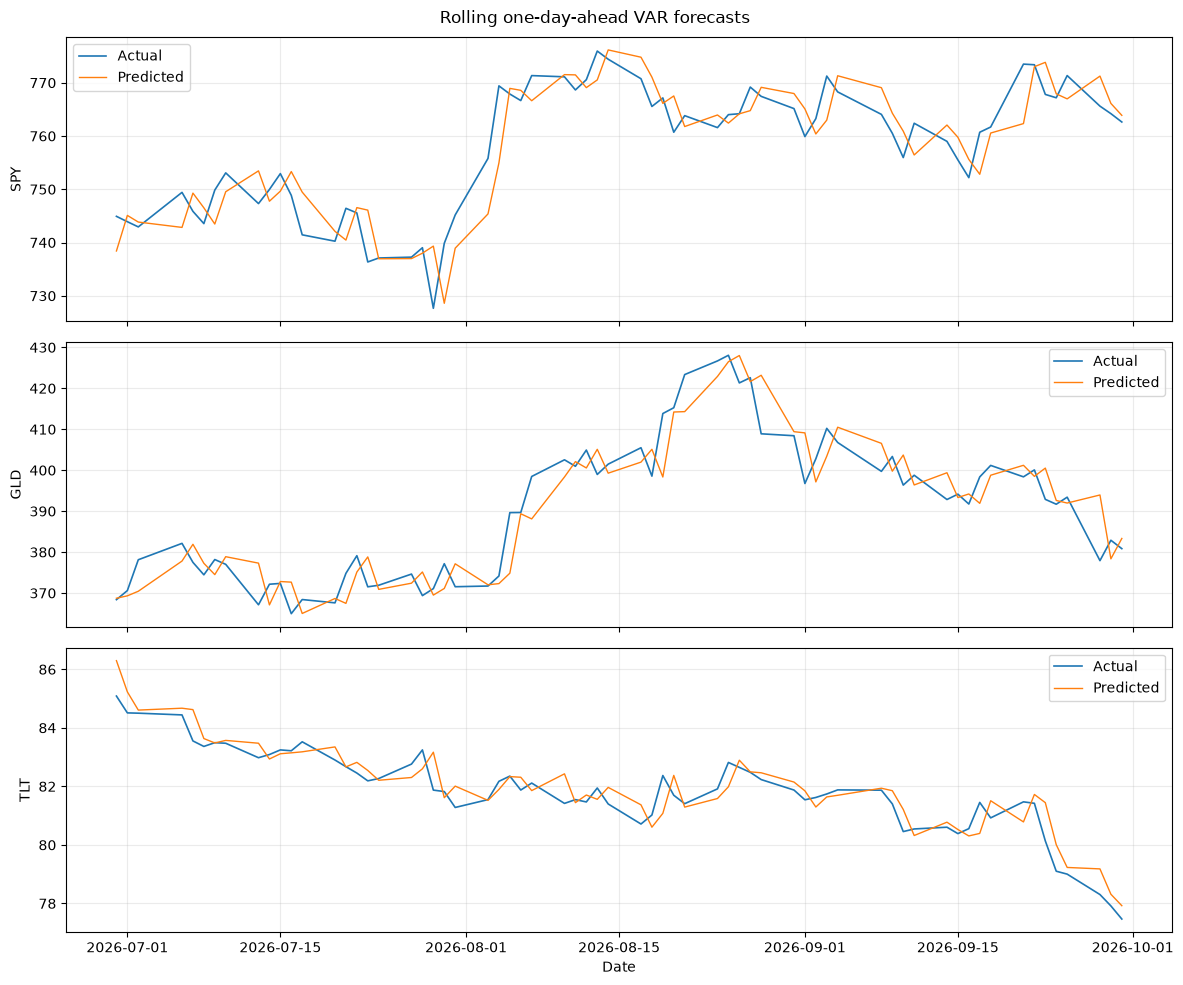

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.vector_ar.var_model import VAR

tickers = ["SPY", "GLD", "TLT"]
prices = yf.download(
    tickers, start="2020-01-01", end="2026-10-01",
    auto_adjust=True, progress=False
)["Close"][tickers].dropna()
if prices.empty:
    raise ValueError("yfinance returned no data.")

# The test set consists of the last three calendar months.
test_start = prices.index.max() - pd.DateOffset(months=3)
train_prices = prices.loc[prices.index < test_start]
test_prices = prices.loc[prices.index >= test_start]
train_diffs = train_prices.diff().dropna()
print(f"Training observations: {len(train_prices)}")
print(f"Test period: {test_prices.index.min().date()} to {test_prices.index.max().date()}")

# Fit candidate VAR models with 0--10 lags and choose the lowest AIC.
max_lag = min(10, max(0, (len(train_diffs) - 1) // 3))
candidate_models = {}
for lag in range(max_lag + 1):
    try:
        candidate_models[lag] = VAR(train_diffs).fit(lag)
    except (ValueError, np.linalg.LinAlgError):
        pass
if not candidate_models:
    raise ValueError("No VAR lag could be fitted.")
aic_table = pd.DataFrame({"lag": list(candidate_models), "AIC": [model.aic for model in candidate_models.values()]})
selected_lag = int(aic_table.loc[aic_table["AIC"].idxmin(), "lag"])
model = candidate_models[selected_lag]
print("AIC by lag:")
display(aic_table.sort_values("lag").round(4))
print(f"Selected lag: {selected_lag}")
print(f"Model stable: {model.is_stable()}")

# Expanding-window rolling-origin forecasts with a one-day horizon.
all_diffs = prices.diff().dropna()
predicted_diffs = []
for date in test_prices.index:
    history = all_diffs.loc[all_diffs.index < date]
    rolling_model = VAR(history).fit(selected_lag)
    if selected_lag == 0:
        forecast = rolling_model.forecast(history.values[-1:], steps=1)[0]
    else:
        forecast = rolling_model.forecast(history.values[-selected_lag:], steps=1)[0]
    predicted_diffs.append(forecast)

predicted_diffs = pd.DataFrame(predicted_diffs, index=test_prices.index, columns=tickers)
predicted_prices = test_prices.copy()
previous_prices = prices.shift(1).loc[test_prices.index]
predicted_prices = previous_prices + predicted_diffs

rmse = pd.Series({
    ticker: np.sqrt(mean_squared_error(test_prices[ticker], predicted_prices[ticker]))
    for ticker in tickers
}, name="RMSE")
print("RMSE of one-day-ahead price forecasts:")
display(rmse.to_frame().round(4))

fig, axes = plt.subplots(len(tickers), 1, figsize=(12, 10), sharex=True)
for ax, ticker in zip(axes, tickers):
    ax.plot(test_prices.index, test_prices[ticker], label="Actual", linewidth=1.2)
    ax.plot(predicted_prices.index, predicted_prices[ticker], label="Predicted", linewidth=1.0)
    ax.set_ylabel(ticker)
    ax.grid(alpha=0.25)
    ax.legend()
axes[-1].set_xlabel("Date")
fig.suptitle("Rolling one-day-ahead VAR forecasts")
fig.tight_layout()
plt.show()

--------
### IRF

IRF ukazuje, ako systém reaguje na jednorazový šok v jednej premennej a ako sa tento účinok vyvíja v nasledujúcich obdobiach.

1. Znamienko odozvy: kladná hodnota znamená pozitívnu reakciu, záporná negatívnu.
2. Veľkosť odozvy: ako výrazne sa daná premenná zmení po šoku.
3. Trvanie odozvy: po koľkých obdobiach účinok približne zaniká.
4. Intervaly spoľahlivosti: či je nulová odozva zlučiteľná s odhadnutou neistotou.

    - Stĺpce predstavujú premennú, v ktorej nastal šok. 
    - Riadky predstavujú premennú, ktorej reakciu sledujeme.
    - Modrá čiara je odhadnutá impulzná odozva.
    - Čierne prerušované čiary predstavujú intervaly neistoty.

Parameter orth=True zabezpečuje výpočet ortogonalizovaných impulzných odoziev pomocou Choleského rozkladu, čím zobrazuje nekorelované šoky jednotlivých premenných. Orth=False zobrazuje korelované šoky.


c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been 

Selected VAR lag by AIC: 3
Model stable: True


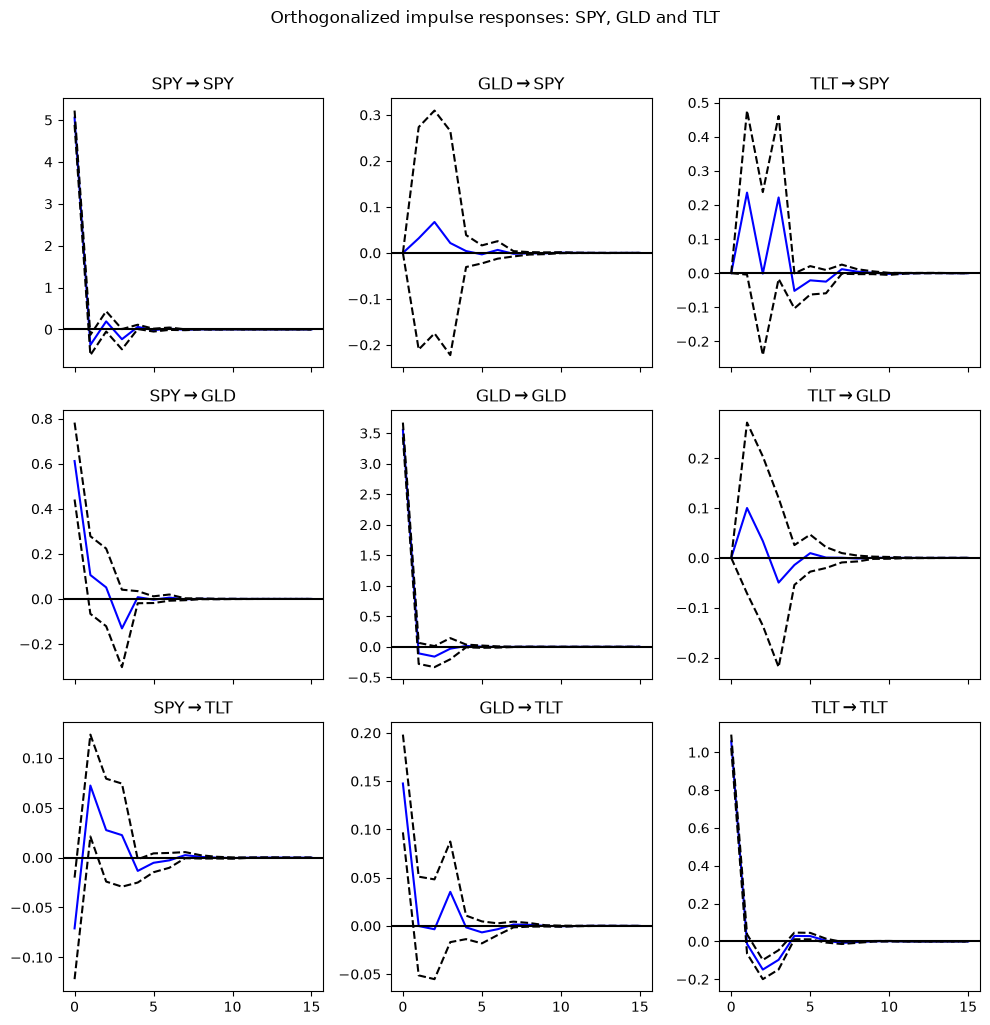

Responses of GLD and TLT to an orthogonalized SPY shock:


,sign at peak,peak horizon (days),peak response,approx. duration (days),near zero at day 15
response to SPY shock,,,,,
GLD,positive,0,0.611756,4,True
TLT,positive,1,0.072360,8,True


Duration is defined as the last horizon where the response is at least 1% of its peak absolute response.


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from statsmodels.tsa.vector_ar.var_model import VAR

tickers = ["SPY", "GLD", "TLT"]
prices = yf.download(
    tickers, start="2020-01-01", end="2026-10-01",
    auto_adjust=True, progress=False
)["Close"][tickers].dropna()
if prices.empty:
    raise ValueError("yfinance returned no data.")

# Use first differences, as in the preceding VAR exercise.
differences = prices.diff().dropna()
candidate_models = {}
for lag in range(11):
    try:
        candidate_models[lag] = VAR(differences).fit(lag)
    except (ValueError, np.linalg.LinAlgError):
        pass
if not candidate_models:
    raise ValueError("No VAR model could be fitted.")
selected_lag = min(candidate_models, key=lambda lag: candidate_models[lag].aic)
model = candidate_models[selected_lag]
print(f"Selected VAR lag by AIC: {selected_lag}")
print(f"Model stable: {model.is_stable()}")

# Orthogonalized responses use a Cholesky decomposition. The ordering is
# SPY, GLD, TLT, so the first shock column is the SPY shock.
irf = model.irf(15)
irf.plot(orth=True)
plt.suptitle("Orthogonalized impulse responses: SPY, GLD and TLT", y=1.02)
plt.tight_layout()
plt.show()

responses = irf.orth_irfs[:, :, 0]
response_table = pd.DataFrame(responses, columns=tickers)
summary_rows = []
for ticker in ["GLD", "TLT"]:
    values = response_table[ticker].to_numpy()
    peak_period = int(np.argmax(np.abs(values)))
    peak_value = values[peak_period]
    threshold = max(abs(peak_value) * 0.01, 1e-12)
    non_negligible = np.flatnonzero(np.abs(values) >= threshold)
    duration = int(non_negligible[-1]) if len(non_negligible) else 0
    summary_rows.append({
        "response to SPY shock": ticker,
        "sign at peak": "positive" if peak_value > 0 else "negative" if peak_value < 0 else "zero",
        "peak horizon (days)": peak_period,
        "peak response": peak_value,
        "approx. duration (days)": duration,
        "near zero at day 15": bool(abs(values[-1]) < threshold),
    })

summary = pd.DataFrame(summary_rows).set_index("response to SPY shock")
print("Responses of GLD and TLT to an orthogonalized SPY shock:")
display(summary.round(6))
print("Duration is defined as the last horizon where the response is at least 1% of its peak absolute response.")

--------
## Stavové modely

Stavové modely (State-Space Models) slúžia na modelovanie časových radov, pri ktorých predpokladáme existenciu skrytého (nepozorovateľného) stavu systému.

Pozorované hodnoty obsahujú informáciu o tomto stave, ale môžu byť ovplyvnené náhodným šumom.


### Matematický zápis stavového modelu

**1. Stavová rovnica – ako sa vyvíja skrytý stav:**

$$
x_t = Fx_{t-1} + w_t
$$

**2. Pozorovacia rovnica – čo v skutočnosti pozorujeme:**

$$
y_t = Hx_t + v_t
$$

kde:

- $x_t$ – skrytý (nepozorovateľný) stav systému,
- $y_t$ – pozorovaná hodnota časového radu,
- $F$ – určuje, ako aktuálny stav závisí od predchádzajúceho stavu,
- $H$ – určuje vzťah medzi skrytým stavom a pozorovaním,
- $w_t$ – stavový šum, teda náhodné zmeny samotného systému,
- $v_t$ – pozorovací šum, teda náhodná chyba merania.

Predpokladáme, že šumy majú nulovú strednú hodnotu, sú nezávislé a majú normálne rozdelenie:

$$
w_t \sim N(0,Q), \qquad v_t \sim N(0,R)
$$

Parametre $Q$ a $R$ predstavujú rozptyly jednotlivých šumov.

### AR(1) ako stavový model

Z predchádzajúcich cvičení poznáme autoregresný model prvého rádu:

$$
x_t = \phi x_{t-1} + w_t
$$

Ak tento proces nepozorujeme priamo, ale iba s náhodnou chybou, môžeme ho zapísať ako stavový model:

**Stavová rovnica:**

$$
x_t = \phi x_{t-1} + w_t
$$

**Pozorovacia rovnica:**

$$
y_t = x_t + v_t
$$

V porovnaní so všeobecným stavovým modelom platí:

$$
F = \phi, \qquad H = 1
$$

### Simulácia AR(1) stavového modelu

Použijeme nasledujúce parametre:

| Parameter |  Význam |
|---|---
| $n$ | Počet simulovaných časových okamihov |
| $\phi$ | Sila závislosti skrytého stavu od jeho minulosti |
| $Q$ | Rozptyl stavového šumu |
| $R$ | Rozptyl pozorovacieho šumu |

**3. Rozdiel medzi $Q$ a $R$**

- Väčšie $Q$ znamená väčšie náhodné zmeny **skutočného skrytého stavu**.
- Väčšie $R$ znamená väčšiu chybu **pozorovaných hodnôt**.

V reálnej situácii však spravidla poznáme iba pozorovania a skrytý stav nevieme priamo určiť.


In [5]:
# Stavová rovnica:       x_t = phi * x_(t-1) + w_t
# Pozorovacia rovnica:   y_t = x_t + v_t
#
# state        = skrytý stav systému
# observations = zašumené pozorovania

import numpy as np
import matplotlib.pyplot as plt

# 1. Parametre stavového modelu
rng = np.random.default_rng(42)

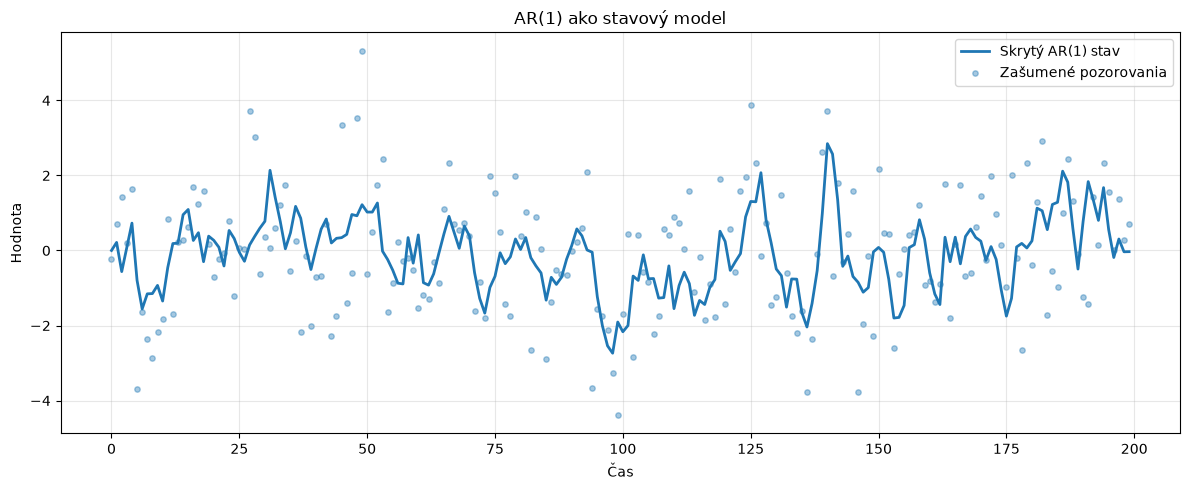

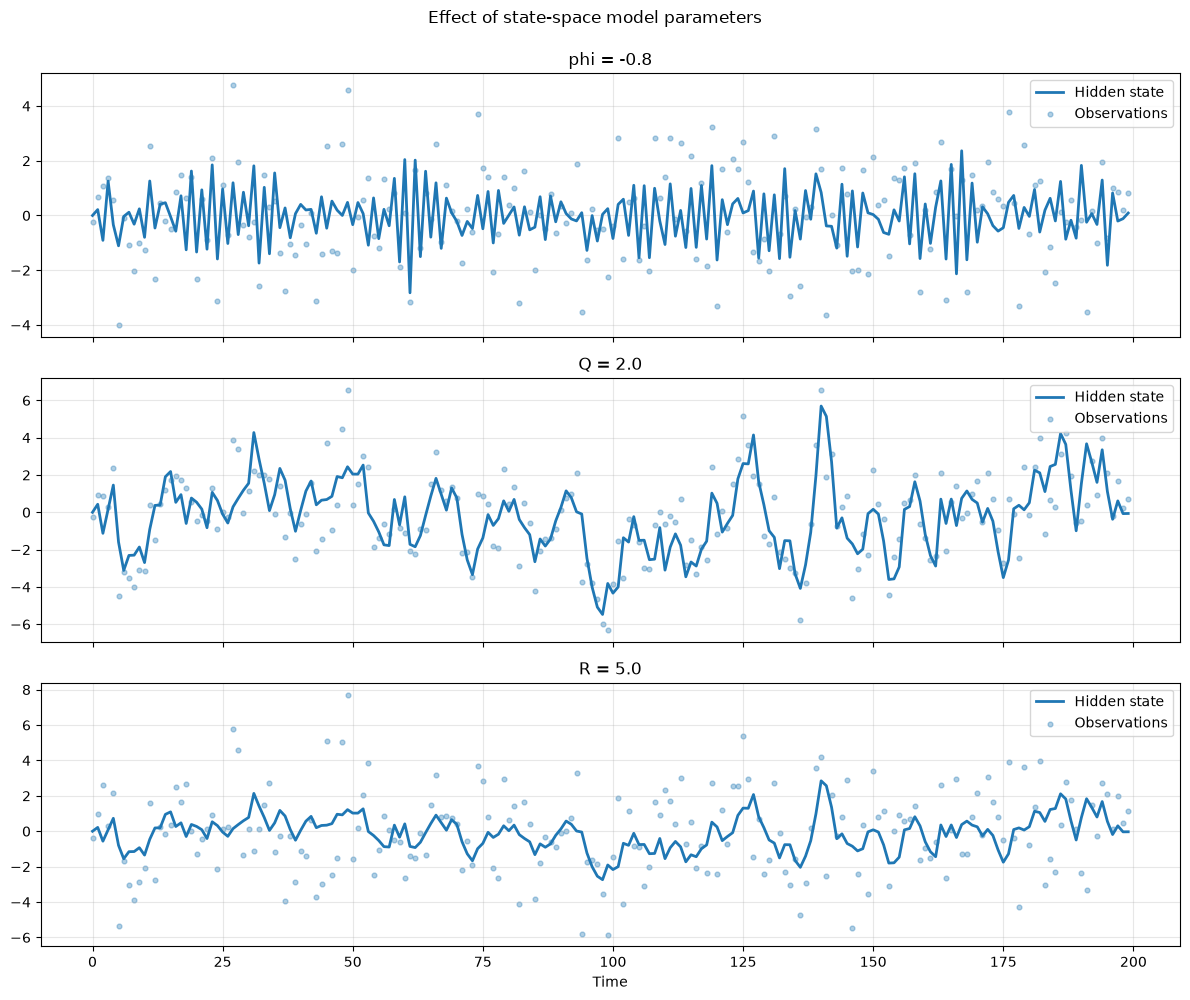

Interpretation:
- Negative phi produces alternating movements in the hidden state.
- Larger Q increases variation in the hidden state itself.
- Larger R increases measurement noise while leaving the hidden state dynamics unchanged.


In [6]:
# 1. Parametre stavového modelu
n = 200
phi = 0.8
Q = 0.5
R = 2.0

# 2. Simulácia skrytého AR(1) stavu
state = np.zeros(n)

for t in range(1, n):
    w_t = rng.normal(0, np.sqrt(Q))
    state[t] = phi * state[t - 1] + w_t

# 3. Vytvorenie zašumených pozorovaní
v = rng.normal(0, np.sqrt(R), size=n)
observations = state + v

#4. Vizualizácia
plt.figure(figsize=(12, 5))

plt.plot(
    state,
    label="Skrytý AR(1) stav",
    linewidth=2
)

plt.scatter(
    range(n),
    observations,
    label="Zašumené pozorovania",
    alpha=0.4,
    s=15
)

plt.title("AR(1) ako stavový model")
plt.xlabel("Čas")
plt.ylabel("Hodnota")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

def simulate_state_space(phi_value=0.8, q_value=0.5, r_value=2.0, seed=42):
    experiment_rng = np.random.default_rng(seed)
    experiment_state = np.zeros(n)
    for time in range(1, n):
        experiment_state[time] = (
            phi_value * experiment_state[time - 1]
            + experiment_rng.normal(0, np.sqrt(q_value))
        )
    experiment_observations = experiment_state + experiment_rng.normal(
        0, np.sqrt(r_value), size=n
    )
    return experiment_state, experiment_observations

experiments = {
    "phi = -0.8": (-0.8, 0.5, 2.0),
    "Q = 2.0": (0.8, 2.0, 2.0),
    "R = 5.0": (0.8, 0.5, 5.0),
}
fig, axes = plt.subplots(len(experiments), 1, figsize=(12, 10), sharex=True)
for axis, (label, parameters) in zip(axes, experiments.items()):
    experiment_state, experiment_observations = simulate_state_space(*parameters)
    axis.plot(experiment_state, label="Hidden state", linewidth=2)
    axis.scatter(range(n), experiment_observations, label="Observations", alpha=0.35, s=12)
    axis.set_title(label)
    axis.grid(alpha=0.3)
    axis.legend()
axes[-1].set_xlabel("Time")
fig.suptitle("Effect of state-space model parameters", y=0.995)
fig.tight_layout()
plt.show()

print("Interpretation:")
print("- Negative phi produces alternating movements in the hidden state.")
print("- Larger Q increases variation in the hidden state itself.")
print("- Larger R increases measurement noise while leaving the hidden state dynamics unchanged.")


## BONUS: 2 Body
1. Analyzuje dáta v súboroch energy.csv, Precious_Metals.csv, Technology.csv a na základe výsledkov rozhodnite, pre ktoré datasety je vhodný VAR a pre ktoré VECM. Aký kointegračný rank bol určený a čo to znamená?
2. Iba pre dataset, pre ktorý je vhodný VECM, vyberte počet lagov pomocou AIC, odhadnite VECM s určeným kointegračným rankom a vykonajte rolling-origin predikciu s horizontom 1 pozorovanie dopredu. Prečo vstupné dáta pre VECM sú premenné v ich pôvodných úrovniach namiesto ich prvých diferencií?
    - dáta nezabudnite rozdeliť a predikciu vykonajte na posledných troch mesiacoch
3. Porovnajte skutočné a predikované hodnoty na grafe a vypočítajte MAE a RMSE.

c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\vector_ar\vecm.py:717: ComplexWarning: Casting complex values to real discards the imaginary part
  lr1[i] = -t * np.sum(tmp, 0)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\vector_ar\vecm.py:718: ComplexWarning: Casting complex values to real discards the imaginary part
  lr2[i] = -t * np.log(1 - a[i])
C:\Users\Admin\AppData\Local\Temp\ipykernel_21292\3939274505.py:16: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return adfuller(series.dropna(), autolag="AIC")[1]
C:\Users\Admin\AppData\Local\Temp\ipykernel_21292\3939274505.py:16: FutureWarning: a

,observations,variables,cointegration rank r,level ADF p-values,recommendation
dataset,,,,,
energy,731,2,2,"Biomass: 0.2173, Geothermal: 0.4775",VECM
Precious_Metals,1760,2,0,"GLD: 0.7267, SLV: 0.3812",VAR in first differences
Technology,1760,3,0,"AAPL: 0.9226, GOOGL: 0.8960, MSFT: 0.9560",VAR in first differences


c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\s

Dataset selected for VECM: energy, rank r = 2
VECM uses levels because the error-correction term models the long-run cointegrating relationship.
Selected VECM lag differences by AIC: 4


c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\s

Rolling one-step-ahead forecast metrics:


c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\s

,MAE,RMSE
Biomass,60.9906,81.8049
Geothermal,0.7612,0.9728


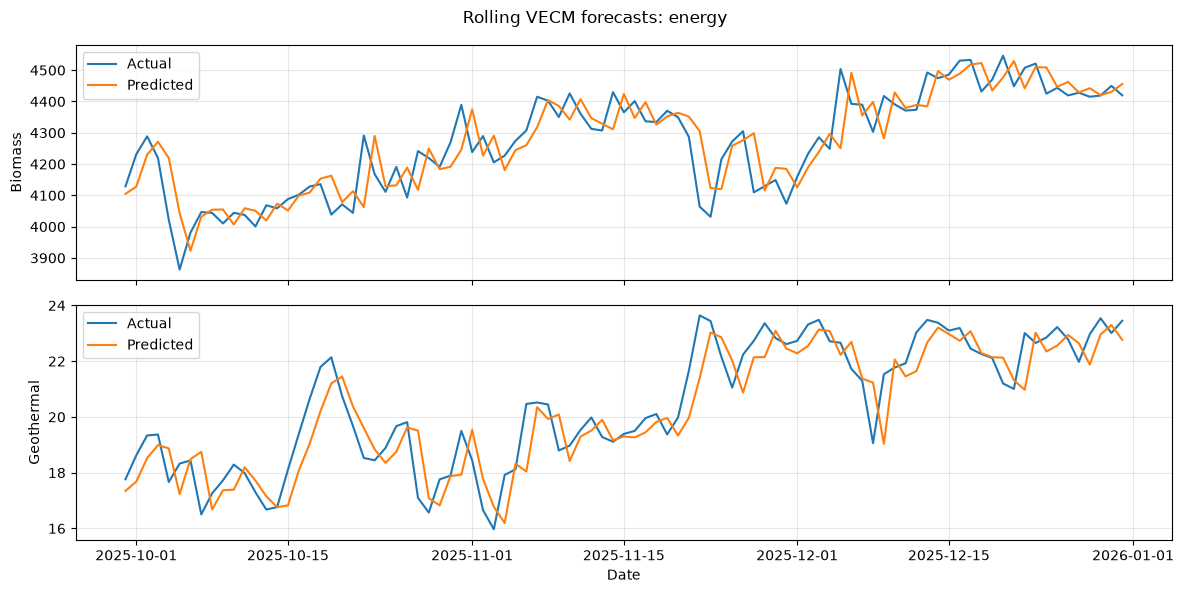

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.vector_ar.vecm import VECM, coint_johansen, select_order

DATASETS = {
    "energy": Path("data") / "energy.csv",
    "Precious_Metals": Path("data") / "Precious_Metals.csv",
    "Technology": Path("data") / "Technology.csv",
}

def adf_pvalue(series):
    return adfuller(series.dropna(), autolag="AIC")[1]

def trace_rank(levels, alpha_column=1):
    result = coint_johansen(levels, det_order=0, k_ar_diff=1)
    for rank, (statistic, critical_value) in enumerate(
        zip(result.lr1, result.cvt[:, alpha_column])
    ):
        if statistic <= critical_value:
            return rank, result
    return levels.shape[1], result

dataset_results = {}
summary_rows = []
for name, path in DATASETS.items():
    if not path.exists():
        raise FileNotFoundError(f"Dataset not found: {path}")
    frame = pd.read_csv(path, parse_dates=["Date"]).set_index("Date").sort_index().dropna()
    levels = frame.select_dtypes(include="number")
    if levels.shape[1] < 2:
        raise ValueError(f"{name} must contain at least two numeric series.")
    rank, johansen = trace_rank(levels)
    pvalues = {column: adf_pvalue(levels[column]) for column in levels}
    dataset_results[name] = {"levels": levels, "rank": rank, "johansen": johansen, "adf": pvalues}
    summary_rows.append({
        "dataset": name,
        "observations": len(levels),
        "variables": levels.shape[1],
        "cointegration rank r": rank,
        "level ADF p-values": ", ".join(f"{column}: {value:.4f}" for column, value in pvalues.items()),
        "recommendation": "VECM" if rank > 0 else "VAR in first differences",
    })

analysis_summary = pd.DataFrame(summary_rows).set_index("dataset")
display(analysis_summary)

vecm_candidates = [name for name, result in dataset_results.items() if result["rank"] > 0]
if not vecm_candidates:
    raise ValueError("No dataset has a positive Johansen cointegration rank.")
vecm_name = vecm_candidates[0]
vecm_levels = dataset_results[vecm_name]["levels"]
vecm_rank = dataset_results[vecm_name]["rank"]
print(f"Dataset selected for VECM: {vecm_name}, rank r = {vecm_rank}")
print("VECM uses levels because the error-correction term models the long-run cointegrating relationship.")

test_start = vecm_levels.index.max() - pd.DateOffset(months=3)
train_levels = vecm_levels.loc[vecm_levels.index < test_start]
test_levels = vecm_levels.loc[vecm_levels.index >= test_start]
if len(train_levels) < 30 or len(test_levels) == 0:
    raise ValueError("The selected dataset is too short for the requested split.")

lag_selection = select_order(train_levels, maxlags=10, deterministic="ci")
selected_k_ar_diff = lag_selection.aic
if selected_k_ar_diff is None or not np.isfinite(selected_k_ar_diff):
    selected_k_ar_diff = 1
selected_k_ar_diff = int(selected_k_ar_diff)
initial_model = VECM(
    train_levels, k_ar_diff=selected_k_ar_diff,
    coint_rank=vecm_rank, deterministic="ci"
).fit()
print(f"Selected VECM lag differences by AIC: {selected_k_ar_diff}")

predictions = []
for date in test_levels.index:
    history = vecm_levels.loc[vecm_levels.index < date]
    rolling_fit = VECM(
        history, k_ar_diff=selected_k_ar_diff,
        coint_rank=vecm_rank, deterministic="ci"
    ).fit()
    predictions.append(rolling_fit.predict(steps=1)[0])
predicted_levels = pd.DataFrame(predictions, index=test_levels.index, columns=vecm_levels.columns)

metrics = pd.DataFrame({
    "MAE": test_levels.apply(lambda actual: mean_absolute_error(actual, predicted_levels[actual.name])),
    "RMSE": test_levels.apply(lambda actual: np.sqrt(mean_squared_error(actual, predicted_levels[actual.name]))),
})
print("Rolling one-step-ahead forecast metrics:")
display(metrics.round(4))

fig, axes = plt.subplots(len(vecm_levels.columns), 1, figsize=(12, 3 * len(vecm_levels.columns)), sharex=True)
axes = np.atleast_1d(axes)
for axis, column in zip(axes, vecm_levels.columns):
    axis.plot(test_levels.index, test_levels[column], label="Actual")
    axis.plot(predicted_levels.index, predicted_levels[column], label="Predicted")
    axis.set_ylabel(column)
    axis.grid(alpha=0.3)
    axis.legend()
axes[-1].set_xlabel("Date")
fig.suptitle(f"Rolling VECM forecasts: {vecm_name}")
fig.tight_layout()
plt.show()
